In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D , MaxPool2D, Dense ,Flatten,GlobalAveragePooling2D
import os 

In [2]:
from google.colab import drive
import zipfile
import cv2
from collections import Counter
from sklearn.preprocessing import LabelEncoder 
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

In [3]:
drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
ZIP_PATH = "/content/drive/MyDrive/data.zip"

with zipfile.ZipFile(ZIP_PATH,"r") as zip:
    zip.extractall("content/data")
    


In [5]:
DATA_DIR= "content/data/Data/"

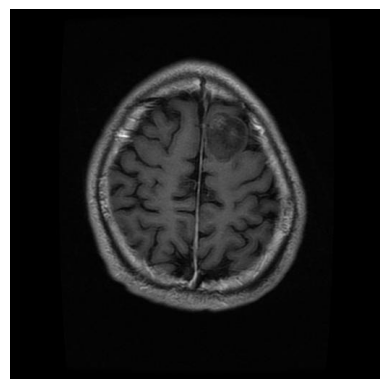

In [6]:
img = cv2.imread(DATA_DIR + "glioma/Tr-gl_0057.jpg" , cv2.COLOR_BGR2RGB)
plt.imshow(img)
plt.axis("off")
plt.show()

## 2. Chargement et préparation des images

In [7]:
VALID_EXTENSION = (".jpg", ".jpeg", ".png", ".bmp")
IMG_SIZE = 224

images =[]
labels =[]

for fld in os.listdir(DATA_DIR):
        
    folder_path = os.path.join(DATA_DIR,fld)
    
    if not os.path.isdir(folder_path):
        continue
    
    label = fld     
    
    for  name in os.listdir(folder_path): 
        
        if not name.lower().endswith(VALID_EXTENSION):
            continue
        
        path = os.path.join(folder_path,name)
        
        try:
            img = cv2.imread(path)
            img = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
            img = cv2.resize(img,(IMG_SIZE,IMG_SIZE))
            
            images.append(img)
            labels.append(label)
            
        except Exception as e:
                print("Error : ",e)
    
print("Nombre total d'images :", len(images))
print("Nombre total de labels :", len(labels))
    
    
    

Nombre total d'images : 7023
Nombre total de labels : 7023


In [8]:
images = np.array(images)
labels = np.array(labels)

print("Shape des images :", images.shape)
print("Shape des labels :", labels.shape)

Shape des images : (7023, 224, 224, 3)
Shape des labels : (7023,)


In [9]:
indices = np.random.permutation(len(images))

images = images[indices]
labels = labels[indices]

print("Images :", images.shape)
print("Labels :", labels.shape)

print("Exemples de labels :", labels[:10])

Images : (7023, 224, 224, 3)
Labels : (7023,)
Exemples de labels : ['notumor' 'pituitary' 'pituitary' 'notumor' 'glioma' 'glioma' 'pituitary'
 'meningioma' 'notumor' 'notumor']


Compter les images par classe et Afficher un graphique avec Matplotlib

notumor : 2000 images
porsentage notumor : 28.477858465043425% 
pituitary : 1757 images
porsentage pituitary : 25.017798661540652% 
glioma : 1621 images
porsentage glioma : 23.0813042859177% 
meningioma : 1645 images
porsentage meningioma : 23.423038587498223% 


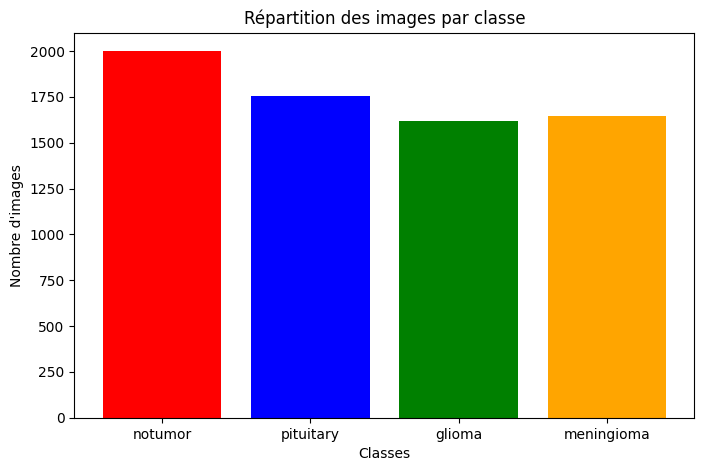

In [10]:
distribution = Counter(labels)

for clas , value in distribution.items():
    print(f"{clas} : {value} images")
    print(f"porsentage {clas} : {(value / len(labels))*100}% ")


plt.figure(figsize=(8, 5))

plt.bar(
    distribution.keys(),
    distribution.values(),
    color=["red", "blue", "green", "orange"]
)

plt.title("Répartition des images par classe")
plt.xlabel("Classes")
plt.ylabel("Nombre d'images")
plt.show()

    

Afficher une image de chaque classe

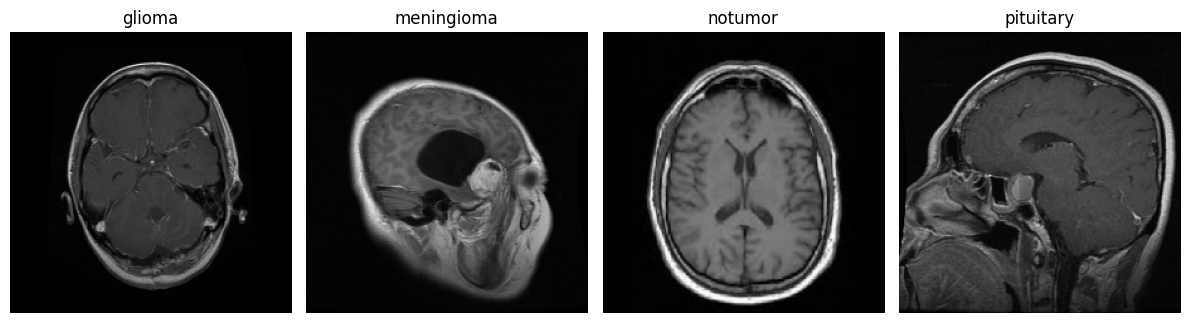

In [11]:
classes = np.unique(labels)

plt.figure(figsize=(12, 4))

for i, classe in enumerate(classes):
    idx = np.where(labels == classe)[0][0]

    plt.subplot(1, len(classes), i + 1)
    plt.imshow(images[idx])
    plt.title(classe)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Utiliser LabelEncoder

In [12]:
encoder = LabelEncoder()

labels_encoded = encoder.fit_transform(labels)

print("Classes :", encoder.classes_)
print("Labels encodés :", labels_encoded[:10])

Classes : ['glioma' 'meningioma' 'notumor' 'pituitary']
Labels encodés : [2 3 3 2 0 0 3 1 2 2]


### normalisation des images

In [1]:
images_before = images.copy()

images = images.astype("float32") / 255.0

print("Minimum :", images.min())
print("Maximum :", images.max())
print("Type :", images.dtype)

NameError: name 'images' is not defined

### Comparer une image avant et après

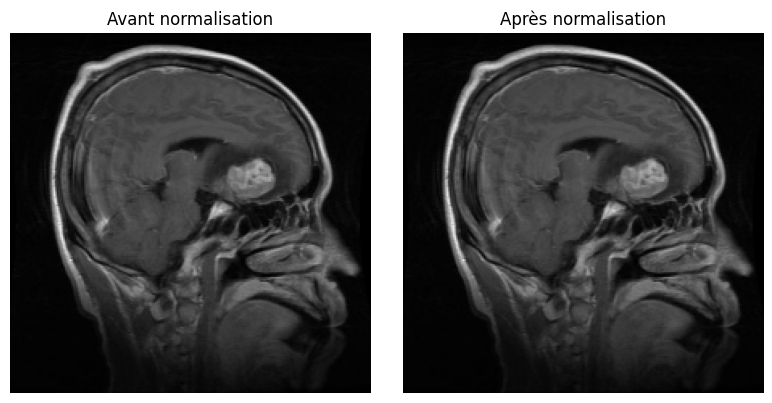

: 

In [ ]:
idx = 0

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(images_before[idx])
axes[0].set_title("Avant normalisation")
axes[0].axis("off")

axes[1].imshow(images[idx])
axes[1].set_title("Après normalisation")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### Créer les couches d'augmentation

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
])

data_augmentation

<Sequential name=sequential, built=False>

: 

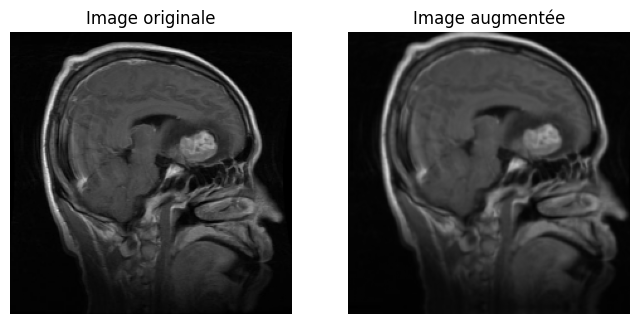

: 

In [ ]:
idx = 0

img = images[idx]

img_batch = tf.expand_dims(img, axis=0)

augmented_img = data_augmentation(
    img_batch,
    training=True
)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Image originale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented_img[0].numpy())
plt.title("Image augmentée")
plt.axis("off")

plt.show()

### Diviser les données en train et test

In [ ]:
x_train , x_test ,y_train , y_test = train_test_split(
    images,
    labels_encoded,
    test_size=0.2,
    random_state=42
)

: 

### Conception du modèle

In [ ]:
model = Sequential(
    [
        layers.Input(shape=(224,224,3)),
        
        Conv2D(32,3,activation="relu",padding="same"),
        MaxPool2D(2),
        
        Conv2D(64,3,activation="relu",padding="same"),
        MaxPool2D(2),
        
        Conv2D(128,3,activation="relu",padding="same"),
        MaxPool2D(2),
        
        GlobalAveragePooling2D(),
        
        Dense(128,activation="relu"),
        
        Dense(4,activation="softmax")
        
    ]
)

model.summary()

NameError: name 'Sequential' is not defined

: 

In [ ]:
model.compile(loss='binary_crossentropy',optimizer= 'adam',metrics=['accuracy'])

: 

In [ ]:
model.fit(x_train,y_train , epochs=5)

: 

: 

: 

: 

: 